# 19. Zeichnen zur Kontrolle

Ein Bild sagt mehr als hundert Zahlen. Wenn dein Programm Rechtecke vergibt, Vögel fliegen lässt oder eine Karte untersucht,
siehst du in einer **Zeichnung** sofort, ob etwas nicht stimmt: ein Rechteck, das überlappt, ein Vogel, der den Wald verlässt,
ein Feld, das falsch markiert ist. Außerdem machen Bilder deine Dokumentation viel anschaulicher.

Zum Zeichnen gibt es die Bibliothek **matplotlib**. Sie läuft auch im Browser (JupyterLite).

In diesem Notebook lernst du:

- Linien, Punkte und Balken zu zeichnen,
- Kreise und Rechtecke einzuzeichnen,
- ein Raster oder eine Tabelle als **Farbbild** darzustellen.

In der Wettbewerbs-Ecke zeichnest du die Landnahme und den Flugplan der Raubvögel aus dem Wintervorrat.

## 1. Linien, Punkte, Balken

Das Grundgerüst ist immer gleich:

```python
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 3))     # neues Bild, 5 breit und 3 hoch (in Zoll)
plt.plot(xs, ys)               # zeichnen ...
plt.title('Überschrift')       # ... beschriften ...
plt.show()                     # ... und anzeigen
```

`xs` und `ys` sind zwei Listen gleicher Länge mit den x- und y-Koordinaten der Punkte.

| Befehl | zeichnet |
|---|---|
| `plt.plot(xs, ys)` | Linie durch die Punkte |
| `plt.plot(xs, ys, 'o')` | nur Punkte (`'o'` Kreis, `'s'` Quadrat, `'^'` Dreieck, `'x'` Kreuz) |
| `plt.plot(xs, ys, 'ro-')` | rote Punkte mit Linie (`r` rot, `g` grün, `b` blau, `k` schwarz) |
| `plt.bar(xs, hoehen)` | Balken |
| `plt.xlabel(...)`, `plt.ylabel(...)`, `plt.title(...)` | Beschriftungen |
| `plt.grid(True)` | Gitterlinien |

In [ ]:
import matplotlib.pyplot as plt

xs = []
ys = []
for x in range(11):
    xs.append(x)
    ys.append(x * x)
plt.figure(figsize=(5, 3))
plt.plot(xs, ys, 'bo-')
plt.xlabel('x')
plt.ylabel('x · x')
plt.title('Quadratzahlen')
plt.grid(True)
plt.show()

#### Aufgabe 1.1

Zeichne als Balkendiagramm, wie oft jede Augensumme mit zwei Würfeln vorkommt (Notebook 10, Aufgabe 3.1). Beschrifte die Achsen.

**So etwa sollte dein Bild aussehen:**

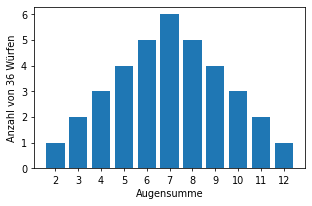

In [ ]:
import matplotlib.pyplot as plt

anzahl = [0] * 13
for w1 in range(1, 7):
    for w2 in range(1, 7):
        anzahl[w1 + w2] = anzahl[w1 + w2] + 1
# dein Code

<details>
<summary>Tipp anzeigen</summary>

Die x-Werte sind die Summen 2 bis 12 (`list(range(2, 13))`), die Höhen `anzahl[2:]`. `plt.xticks(summen)` schreibt jede Summe
unter ihren Balken.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt

anzahl = [0] * 13
for w1 in range(1, 7):
    for w2 in range(1, 7):
        anzahl[w1 + w2] = anzahl[w1 + w2] + 1
summen = list(range(2, 13))
plt.figure(figsize=(5, 3))
plt.bar(summen, anzahl[2:])
plt.xlabel('Augensumme')
plt.ylabel('Anzahl von 36 Würfen')
plt.xticks(summen)
plt.show()
```

</details>

## 2. Punkte und Kreise auf einer Karte

Bei Karten ist wichtig, dass ein Meter in x-Richtung genauso lang aussieht wie in y-Richtung. Sonst werden Kreise zu Ellipsen.
Das erreichst du mit `plt.gca().set_aspect('equal')`. (`plt.gca()` heißt „die aktuellen Achsen“, das ist die Zeichenfläche.)

Einen Kreis fügst du so hinzu:

```python
plt.gca().add_patch(plt.Circle((x, y), radius, fill=False))
```

#### Aufgabe 2.1

Zeichne die Häuser und die geplanten Windräder aus Notebook 9 (Zum Winde verweht): Häuser als schwarze Quadrate, Windräder als
rote Dreiecke. Zeichne um jedes Windrad einen gestrichelten Kreis bis zum nächsten Haus. Dann siehst du, dass auf jedem Kreis
genau ein Haus liegt (oder mehrere gleich weit entfernte) und keines darin.

**So etwa sollte dein Bild aussehen:**

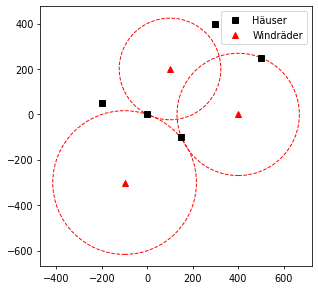

In [ ]:
import matplotlib.pyplot as plt

hx = [0, 300, 150, -200, 500]
hy = [0, 400, -100, 50, 250]
wx = [100, 400, -100]
wy = [200, 0, -300]


def naechstes_haus(x, y):
    kleinster = None
    for i in range(len(hx)):
        d = ((x - hx[i]) ** 2 + (y - hy[i]) ** 2) ** 0.5
        if kleinster is None or d < kleinster:
            kleinster = d
    return kleinster


# dein Code

<details>
<summary>Tipp anzeigen</summary>

Zwei Aufrufe von `plt.plot` mit `'ks'` und `'r^'`, dann für jedes Windrad `plt.gca().add_patch(plt.Circle(...))` mit
`fill=False, linestyle='--'`. Mit `label='...'` und `plt.legend()` bekommst du eine Erklärung der Zeichen.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt

hx = [0, 300, 150, -200, 500]
hy = [0, 400, -100, 50, 250]
wx = [100, 400, -100]
wy = [200, 0, -300]


def naechstes_haus(x, y):
    kleinster = None
    for i in range(len(hx)):
        d = ((x - hx[i]) ** 2 + (y - hy[i]) ** 2) ** 0.5
        if kleinster is None or d < kleinster:
            kleinster = d
    return kleinster


plt.figure(figsize=(5, 5))
plt.plot(hx, hy, 'ks', label='Häuser')
plt.plot(wx, wy, 'r^', label='Windräder')
for i in range(len(wx)):
    r = naechstes_haus(wx[i], wy[i])
    plt.gca().add_patch(plt.Circle((wx[i], wy[i]), r, fill=False, linestyle='--', color='red'))
plt.gca().set_aspect('equal')
plt.legend()
plt.show()
```

</details>

## 3. Rechtecke

Ein Rechteck mit der linken unteren Ecke `(x, y)`, der Breite `b` und der Höhe `h` zeichnest du mit

```python
plt.gca().add_patch(plt.Rectangle((x, y), b, h, color='green', alpha=0.5))
```

`alpha=0.5` macht das Rechteck halb durchsichtig. So sieht man Überlappungen. Weil Rechtecke den Bildausschnitt nicht von selbst
vergrößern, legst du ihn mit `plt.xlim(...)` und `plt.ylim(...)` fest. Mit `plt.text(x, y, 'Text')` kannst du etwas
hineinschreiben.

## 4. Raster und Tabellen als Farbbild

Eine Tabelle aus Zahlen (Notebook 11) zeigt `plt.imshow(tabelle)` als Bild: Jede Zelle wird ein Farbkästchen, große Zahlen
bekommen eine andere Farbe als kleine. Zeile 0 ist oben, Spalte 0 links, genau wie in deiner Tabelle.

- `cmap='gray_r'` färbt 0 weiß und den größten Wert schwarz, `cmap='Reds'` von weiß nach rot.
- `plt.colorbar()` zeigt eine Skala, welche Farbe welcher Zahl entspricht.
- Mit `plt.xticks(...)` und `plt.yticks(...)` beschriftest du Spalten und Zeilen.

#### Aufgabe 4.1

Zeichne Kassiopeias Land (`daten/kassiopeia.txt`, Notebook 12): Schwarze Felder schwarz, weiße Felder weiß, Kassiopeia als roter
Punkt. Baue dazu aus der Karte eine Tabelle aus 0 (weiß) und 1 (schwarz).

**So etwa sollte dein Bild aussehen:**

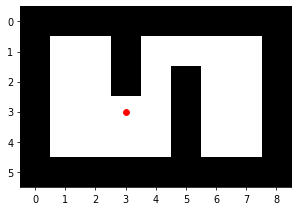

In [ ]:
import matplotlib.pyplot as plt

with open('daten/kassiopeia.txt', encoding='utf-8') as f:
    zeilen = f.read().splitlines()
karte = zeilen[1:]
tabelle = []
# dein Code

<details>
<summary>Tipp anzeigen</summary>

Für jede Zeile eine Liste `reihe` aus 0 und 1 bauen und an `tabelle` anhängen. Kassiopeias Zeile `kz` und Spalte `ks` merken.
Achtung: `plt.plot` erwartet zuerst x (die Spalte), dann y (die Zeile): `plt.plot(ks, kz, 'ro')`.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt

with open('daten/kassiopeia.txt', encoding='utf-8') as f:
    zeilen = f.read().splitlines()
karte = zeilen[1:]
tabelle = []
for z in range(len(karte)):
    reihe = []
    for s in range(len(karte[z])):
        if karte[z][s] == '#':
            reihe.append(1)
        else:
            reihe.append(0)
        if karte[z][s] == 'K':
            kz = z
            ks = s
    tabelle.append(reihe)
plt.figure(figsize=(5, 3.5))
plt.imshow(tabelle, cmap='gray_r')
plt.plot(ks, kz, 'ro')
plt.show()
```

</details>

#### Aufgabe 4.2

Zeichne den Bällebad-Nutzungsplan (Notebook 11) als Farbbild: Zeilen sind die Wochentage, Spalten die Stunden von 7 bis 19 Uhr,
die Farbe zeigt die Zahl der Bälle. Beschrifte die Zeilen mit den Tagen und füge eine Farbskala hinzu.

**So etwa sollte dein Bild aussehen:**

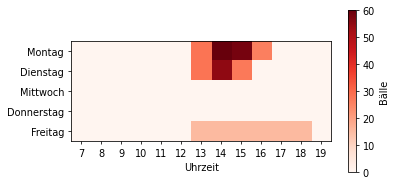

In [ ]:
import matplotlib.pyplot as plt

WOCHENTAGE = ['Montag', 'Dienstag', 'Mittwoch', 'Donnerstag', 'Freitag']
with open('daten/baellebad.txt', encoding='utf-8') as f:
    zeilen = f.read().splitlines()
plan = []
for t in range(5):
    plan.append([0] * 24)
for i in range(1, int(zeilen[0]) + 1):
    teile = zeilen[i].split()
    t = WOCHENTAGE.index(teile[1])
    for stunde in range(int(teile[2]), int(teile[3])):
        plan[t][stunde] = plan[t][stunde] + int(teile[4])
# dein Code

<details>
<summary>Tipp anzeigen</summary>

Für jeden Tag nur die Stunden 7 bis 19 nehmen: `plan[t][7:20]`. Dann `plt.imshow(ausschnitt, cmap='Reds')`,
`plt.colorbar()`, `plt.yticks(range(5), WOCHENTAGE)` und `plt.xticks(range(13), range(7, 20))`.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt

WOCHENTAGE = ['Montag', 'Dienstag', 'Mittwoch', 'Donnerstag', 'Freitag']
with open('daten/baellebad.txt', encoding='utf-8') as f:
    zeilen = f.read().splitlines()
plan = []
for t in range(5):
    plan.append([0] * 24)
for i in range(1, int(zeilen[0]) + 1):
    teile = zeilen[i].split()
    t = WOCHENTAGE.index(teile[1])
    for stunde in range(int(teile[2]), int(teile[3])):
        plan[t][stunde] = plan[t][stunde] + int(teile[4])

ausschnitt = []
for t in range(5):
    ausschnitt.append(plan[t][7:20])
plt.figure(figsize=(6, 3))
plt.imshow(ausschnitt, cmap='Reds')
plt.colorbar(label='Bälle')
plt.yticks(range(5), WOCHENTAGE)
plt.xticks(range(13), range(7, 20))
plt.xlabel('Uhrzeit')
plt.show()
```

Das dunkelste Feld ist Montag 14 Uhr mit 60 Bällen. Auf einen Blick sieht man auch, dass am Mittwoch und Donnerstag gar
niemand Sport hat. So ein Bild ist für die Dokumentation viel anschaulicher als eine Tabelle mit 120 Zahlen.

</details>

## Wettbewerbs-Ecke 1: Landnahme als Bild

*Angelehnt an die Junioraufgabe „Landnahme“ (Bundeswettbewerb Informatik 2015).*

Die Aufgabe hatte eine freiwillige Zusatzaufgabe: „Erstelle eine nette Visualisierung der Landnahme.“ Hier sind die Anträge
aus Notebook 17 und ein paar weitere. Genehmigte Rechtecke sollen grün, abgelehnte rot und gestrichelt erscheinen.

#### Aufgabe E.1

Bearbeite die Anträge wie in Notebook 17, Aufgabe E.1, und zeichne jedes Rechteck: genehmigte grün und halb durchsichtig,
abgelehnte nur als rot gestrichelten Rand. Schreibe die Nummer des Antrags in die Mitte des Rechtecks.

**Erwartete Ausgabe:**
```
Genehmigt: 5 von 7
```

**So etwa sollte dein Bild aussehen:**

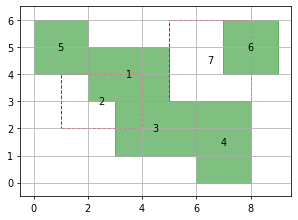

In [ ]:
import matplotlib.pyplot as plt

antraege = [[2, 3, 5, 5], [1, 2, 4, 4], [3, 1, 6, 3], [6, 3, 8, 0], [0, 4, 2, 6], [7, 4, 9, 6], [5, 6, 8, 3]]


def rechtecke_ueberlappen(r, s):
    return r[0] < s[2] and s[0] < r[2] and r[1] < s[3] and s[1] < r[3]


# dein Code

<details>
<summary>Tipp anzeigen</summary>

Erst wie in Notebook 17 entscheiden, dann zeichnen. Für abgelehnte: `fill=False, color='red', linestyle='--'`. Die Mitte ist
`r[0] + breite / 2`, `r[1] + hoehe / 2`; `ha='center', va='center'` setzt den Text genau dorthin.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt

antraege = [[2, 3, 5, 5], [1, 2, 4, 4], [3, 1, 6, 3], [6, 3, 8, 0], [0, 4, 2, 6], [7, 4, 9, 6], [5, 6, 8, 3]]


def rechtecke_ueberlappen(r, s):
    return r[0] < s[2] and s[0] < r[2] and r[1] < s[3] and s[1] < r[3]


genehmigte = []
plt.figure(figsize=(5, 4))
for nr in range(len(antraege)):
    a = antraege[nr]
    r = [min(a[0], a[2]), min(a[1], a[3]), max(a[0], a[2]), max(a[1], a[3])]
    frei = True
    for g in genehmigte:
        if rechtecke_ueberlappen(r, g):
            frei = False
    breite = r[2] - r[0]
    hoehe = r[3] - r[1]
    if frei:
        genehmigte.append(r)
        plt.gca().add_patch(plt.Rectangle((r[0], r[1]), breite, hoehe, color='green', alpha=0.5))
    else:
        plt.gca().add_patch(plt.Rectangle((r[0], r[1]), breite, hoehe, fill=False, color='red', linestyle='--'))
    plt.text(r[0] + breite / 2, r[1] + hoehe / 2, str(nr + 1), ha='center', va='center')
plt.xlim(-0.5, 9.5)
plt.ylim(-0.5, 6.5)
plt.gca().set_aspect('equal')
plt.grid(True)
plt.show()
print('Genehmigt:', len(genehmigte), 'von', len(antraege))
```

Im Bild sieht man, warum Antrag 7 abgelehnt wird: Er überdeckt einen Teil von Antrag 6. Antrag 1 und Antrag 4 berührt er
nur an Kanten, das allein wäre erlaubt. Antrag 4 berührt Antrag 3 an der Kante x = 6 und Antrag 5 berührt Antrag 1 an der
Kante x = 2, beide sind genehmigt. Antrag 2 überlappt mit Antrag 3, wurde aber schon vorher abgelehnt, also zählt das nicht.
Wer sich bei einer Regel unsicher ist, zeichnet am besten.

</details>

#### Frage E.2

Angenommen, im Programm stünde in `rechtecke_ueberlappen` überall `<=` statt `<`. Welche Rechtecke wären im Bild dann
anders gefärbt? Überlege es dir am Bild, und probiere es dann aus.

✏️ *Deine Antwort (Doppelklick zum Bearbeiten):*

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

Mit `<=` würde schon **Berühren** als Überlappen zählen. Dann würden Antrag 3 (berührt Antrag 1 an der Kante y = 3) und
Antrag 5 (berührt Antrag 1 an der Kante x = 2) rot. Antrag 4 bliebe grün: Er berührt nur Antrag 3, und der wäre ja jetzt
abgelehnt. Probier es aus und vergleiche die Bilder. Im Bild sieht man so einen Fehler
sofort, in einer Liste mit „genehmigt“ und „abgelehnt“ kaum.

</details>

## Wettbewerbs-Ecke 2: Der Flugplan im Wintervorrat

*Angelehnt an die Junioraufgabe „Wintervorrat“ (Bundeswettbewerb Informatik 2017).*

In Notebook 13 hast du eine Zeitleiste aus `#` und `.` ausgegeben. Als Bild ist sie viel übersichtlicher.

#### Aufgabe E.3

Simuliere die beiden Vögel wie in Notebook 13 (der Code steht im Gerüst) und zeichne die Tabelle `ueberflogen` als Bild: eine
Zeile pro Feld, eine Spalte pro Minute, überflogen schwarz. Beschrifte die Zeilen mit „Feld 1“ bis „Feld 8“.

**So etwa sollte dein Bild aussehen:**

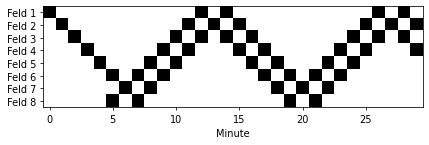

In [ ]:
import matplotlib.pyplot as plt


def schritt(pos, richtung, n):
    if pos + richtung < 1 or pos + richtung > n:
        richtung = -richtung
    return pos + richtung, richtung


n = 8
dauer = 30
starts = [0, 5]
positionen = [1, 8]
richtungen = [1, -1]
ueberflogen = []
for feld in range(n + 1):
    ueberflogen.append([0] * dauer)
for v in range(len(starts)):
    pos = positionen[v]
    richtung = richtungen[v]
    for minute in range(starts[v], dauer):
        ueberflogen[pos][minute] = 1
        pos, richtung = schritt(pos, richtung, n)
# dein Code

<details>
<summary>Tipp anzeigen</summary>

Zeile 0 der Tabelle ist leer, darum zeichnest du `ueberflogen[1:]`. Die Beschriftungen baust du als Liste von Texten und gibst
sie mit `plt.yticks(range(n), namen)` an.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt


def schritt(pos, richtung, n):
    if pos + richtung < 1 or pos + richtung > n:
        richtung = -richtung
    return pos + richtung, richtung


n = 8
dauer = 30
starts = [0, 5]
positionen = [1, 8]
richtungen = [1, -1]
ueberflogen = []
for feld in range(n + 1):
    ueberflogen.append([0] * dauer)
for v in range(len(starts)):
    pos = positionen[v]
    richtung = richtungen[v]
    for minute in range(starts[v], dauer):
        ueberflogen[pos][minute] = 1
        pos, richtung = schritt(pos, richtung, n)

namen = []
for feld in range(1, n + 1):
    namen.append('Feld ' + str(feld))
plt.figure(figsize=(7, 3))
plt.imshow(ueberflogen[1:], cmap='gray_r')
plt.yticks(range(n), namen)
plt.xlabel('Minute')
plt.show()
```

Man sieht die Zickzack-Linien der beiden Vögel und dazwischen die freien Flächen. Die großen weißen Flächen ganz oben und ganz
unten sind die sicheren Zeiten an den Rändern des Weges. In der echten Aufgabe mit einem Rechteckwald zeichnet man die sicheren
Felder als farbige Karte. Siehe `jwinf3/36_Wintervorrat/wintervorrat_loesung.ipynb`.

</details>

## Das hast du gelernt

| Befehl | Wofür |
|---|---|
| `import matplotlib.pyplot as plt` | einmal am Anfang |
| `plt.figure(figsize=(b, h))` … `plt.show()` | ein neues Bild beginnen und anzeigen |
| `plt.plot(xs, ys, 'ro-')` | Punkte und Linien (Farbe, Zeichen, Linie) |
| `plt.bar(xs, hoehen)` | Balkendiagramm |
| `plt.gca().add_patch(plt.Circle(...))` | Kreis |
| `plt.gca().add_patch(plt.Rectangle((x, y), b, h, ...))` | Rechteck (`alpha` für durchsichtig, `fill=False` nur Rand) |
| `plt.gca().set_aspect('equal')` | gleiche Maßstäbe in x und y |
| `plt.imshow(tabelle, cmap='...')` | Tabelle oder Raster als Farbbild |
| `plt.xticks`, `plt.yticks`, `plt.colorbar`, `plt.legend`, `plt.text` | Beschriftungen |

- **Zeichne früh**, nicht erst für die Dokumentation: Fehler sieht man im Bild oft sofort.
- Bilder aus dem Notebook kannst du per Rechtsklick speichern und in die Dokumentation einfügen.

Weiter geht es mit Notebook 20: Bilder als Daten, also Pixel und Farben.